# Lab 07 — Deep learning I: a first neural network and a CNN for images

*Train a dense network and a convolutional network on photos of wood defects*

**Goal.** Turn the images into tensors, write one training loop and read its curves, compare a dense network with a convolutional one against the classical baseline from Lab 4, look at what the CNN learned and where it fails, and save the weights with a model card.

**Data.** `all_datasets/unsupervised/wood_surface_defects/wood_defects.npz`, the wood-defect images from Lab 4

**Reading.** Chapter 21: neural networks, CNNs and sequence models.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab07_deep_learning_cnn/lab07_deep_learning_cnn_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab07_deep_learning_cnn/lab07_deep_learning_cnn_worked.py`.

**Evidence.** `results/lab07/` — training curves, test metrics, confusion matrix, misread images, learned filters and feature maps; `models/wood_cnn.pt` and its card

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Turn the images into tensors, with Lab 4's board-wise splits | 2 |
| B | Build a dense network, write the training loop, read the curves | 3–5 |
| C | Build and train a CNN; test it once; inspect its mistakes and filters | 6–10 |
| D | Save the weights with a card and reload them | 11 |
| Finish | Save the evidence; then train longer and try a one-block CNN | 12–14 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab07/`, and the weights to `models/`.

**PyTorch and the device.** `start_pytorch()` imports PyTorch; if it is missing from the Python that runs this kernel, it installs the CPU build once and carries on. It then picks `DEVICE`: an NVIDIA GPU (`cuda`) or Apple GPU (`mps`) when PyTorch can see one, otherwise the CPU. Everything later is written once and runs on whichever device was chosen. The numbers on the lab sheet come from a CPU run; a GPU run differs in the last digits.

If the first line printed is not the Python you installed PyTorch into, switch the kernel: *Kernel > Change Kernel* in Jupyter, or the interpreter picker in VS Code.

### Question 1 — Setup

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab, start_pytorch

# 2. PyTorch: installed once if missing; then the device to train on (a GPU if PyTorch can see one, else the CPU).
DEVICE = start_pytorch()
import torch
from torch import nn

# 3. The other libraries this lab uses.
import re
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit      # keep each board on one side of a split

# 4. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab07")

Python 3.13.9 at C:\ProgramData\anaconda3\python.exe
PyTorch 2.11.0+cu128 | device: cpu


course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab07/ and models/


## Part A — Images as tensors

**Goal.** Turn the defect images into tensors, with the same board-wise splits as Lab 4.

*Question 2 · Data: wood surface defects*

### Question 2 — Turn images into tensors

The same defect photos as Lab 4: 32 by 32 pixels with three colour values from 0 to 255. PyTorch works on *tensors*, arrays that remember how to compute gradients. A convolutional layer expects images as (batch, channels, height, width), so each image becomes $3\times32\times32$, scaled to $[0,1]$. The splits repeat Lab 4's, with the same seeds: whole boards go to fitting, validation or test, and the test images stay closed until Question 8.

fit: (9357, 3, 32, 32)  validation: (3210, 3, 32, 32)  test: (3134, 3, 32, 32)


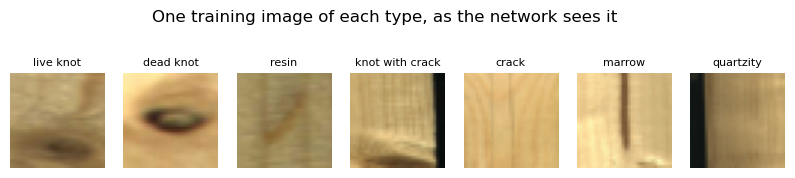

In [2]:
wood = np.load(DATA / "unsupervised/wood_surface_defects/wood_defects.npz")
class_names = [str(name) for name in wood["classes"]]
labels, boards = wood["y"], wood["board"]

# Lab 4's board-wise splits, with the same seeds, so the test boards are the ones Lab 4's PCA model saw.
dev, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42).split(labels, labels, boards))
fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(dev, labels[dev], boards[dev]))
fit, val = dev[fit], dev[val]

def to_tensors(rows):
    """Images as (images, channels, height, width) with values in [0, 1], and labels as whole numbers."""
    X = torch.tensor(wood["x"][rows], dtype=torch.float32).permute(0, 3, 1, 2) / 255.0    # colour first
    return X.to(DEVICE), torch.tensor(labels[rows], dtype=torch.long).to(DEVICE)

X_fit, y_fit = to_tensors(fit)
X_val, y_val = to_tensors(val)
X_test, y_test = to_tensors(test)
print("fit:", tuple(X_fit.shape), " validation:", tuple(X_val.shape), " test:", tuple(X_test.shape))

fig, axes = plt.subplots(1, 7, figsize=(10, 1.9))
for ax, k in zip(axes, range(7)):
    first = int(torch.nonzero(y_fit == k)[0])                  # the first training image of each type
    ax.imshow(X_fit[first].permute(1, 2, 0).cpu())            # matplotlib wants height x width x colour
    ax.set_title(class_names[k], fontsize=8)
    ax.axis("off")
plt.suptitle("One training image of each type, as the network sees it", y=1.08)
plt.savefig(RESULTS / "one_training_image_of_each_type.png", dpi=160, bbox_inches="tight")
plt.show()

**Checkpoint: before you move on**

- 9,357 images to fit, 3,210 to validate, and 3,134 sealed for the test, each $3\times32\times32$.

## Part B — A first neural network and the training loop

**Goal.** Build a dense network, write the training loop, and read its accuracy curves.

*Questions 3–5 · Data: wood surface defects*

### Question 3 — Build a dense network

A dense network flattens the 3,072 numbers of an image into a vector, computes 128 weighted sums, passes each through ReLU, and computes 7 class scores from those. Written in `nn.Sequential`, it is four lines.

In [3]:
def make_mlp():
    """A dense network: 3,072 pixel values -> 128 hidden units with ReLU -> 7 class scores."""
    return nn.Sequential(
        nn.Flatten(),                 # 3 x 32 x 32  ->  3,072
        nn.Linear(3 * 32 * 32, 128), nn.ReLU(),
        nn.Linear(128, 7),            # seven class scores
    )

mlp = make_mlp().to(DEVICE)
print(mlp)
print("trainable weights:", sum(p.numel() for p in mlp.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=7, bias=True)
)
trainable weights: 394247


### Question 4 — Write the training loop and train

The training loop is the whole method. Each epoch shuffles the training images and walks through them in batches of 128. For each batch: compute the class scores (forward pass), compute the cross-entropy loss, compute every gradient with `backward()`, and let the optimizer move every weight a small step. After each epoch, accuracy is recorded on the training and validation images. `predict` works in chunks of 2,000 so that scoring many images never needs them all in memory at once.

In [4]:
def predict(model, X, batch_size=2000):
    """Class predictions in chunks, so a big test set never has to fit in memory at once."""
    model.eval()                                     # evaluation mode: dropout off
    with torch.no_grad():                            # no gradients needed just to predict
        chunks = [model(X[i:i + batch_size]).argmax(dim=1) for i in range(0, len(X), batch_size)]
    return torch.cat(chunks)

def accuracy(model, X, y):
    return (predict(model, X) == y).float().mean().item()

def train_classifier(model, X, y, X_v, y_v, epochs=10, lr=1e-3, batch_size=128):
    """The training loop: shuffle, then for every batch predict, measure the loss, and step downhill.
    Returns the training and validation accuracy after each epoch."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train": [], "validation": []}
    for epoch in range(epochs):
        model.train()                                # training mode: dropout on
        order = torch.randperm(len(X))               # a new shuffle every epoch
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()                    # forget the previous gradients
            loss = loss_fn(model(X[batch]), y[batch])
            loss.backward()                          # backpropagation: gradient for every weight
            optimizer.step()                         # move every weight a small step
        history["train"].append(accuracy(model, X, y))
        history["validation"].append(accuracy(model, X_v, y_v))
    return history

torch.manual_seed(42)
mlp_history = train_classifier(mlp, X_fit, y_fit, X_val, y_val)
print("dense network: validation accuracy by epoch =", [round(a, 3) for a in mlp_history["validation"]])

dense network: validation accuracy by epoch = [0.408, 0.48, 0.552, 0.554, 0.536, 0.485, 0.561, 0.539, 0.596, 0.556]


### Question 5 — Read the accuracy curves

The two curves from Question 4, drawn per epoch.

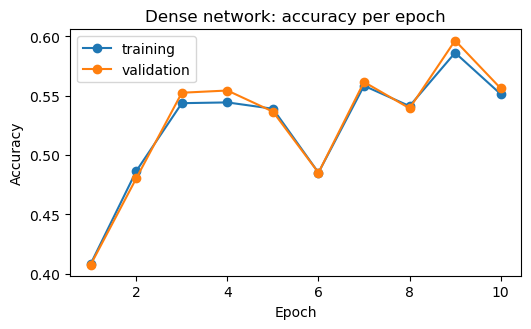

In [5]:
def plot_history(history, title):
    """Training and validation accuracy against the epoch; the title doubles as the file name."""
    epochs = range(1, len(history["train"]) + 1)
    plt.figure(figsize=(5.5, 3.4))
    plt.plot(epochs, history["train"], marker="o", label="training")
    plt.plot(epochs, history["validation"], marker="o", label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    file_name = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_") + ".png"
    plt.savefig(RESULTS / file_name, dpi=160, bbox_inches="tight")
    plt.show()

plot_history(mlp_history, "Dense network: accuracy per epoch")

**What the output shows.** 9,357 images to fit and 3,210 to validate, each three channels of $32\times32$ values in [0, 1]. The dense network has 394,247 weights, almost all of them in its first layer ($3{,}072\times128$). Its training and validation curves zigzag together, between 0.485 and 0.596, and end at 0.556 on validation: not overfitting, which would open a gap between them, but an optimizer that lands somewhere new each epoch. A dense network must learn every pattern separately at every position, and 9,357 images are few for that.

**Checkpoint: before you move on**

- The dense network has 394,247 weights.
- Its training and validation curves zigzag together between 0.49 and 0.60, ending at 0.556 on validation.

## Part C — A convolutional network

**Goal.** Build a CNN, compare it with the dense network on the test images, and look at its mistakes and filters.

*Questions 6–10 · Data: wood surface defects*

### Question 6 — Build a CNN and trace its shapes

A CNN keeps the image as a grid. The first layer slides sixteen $3\times3$ filters, each reading all three colours, across it and produces sixteen feature maps; max pooling halves each map; a second layer does the same with thirty-two filters; the result is flattened and classified by a small dense layer. Printing the shape after each stage shows where the numbers go.

In [6]:
def make_cnn():
    """Two blocks of convolution, ReLU and pooling, then a small dense classifier."""
    return nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 x 16 x 16
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 32 x 8 x 8
        nn.Flatten(),                                                             # 2,048
        nn.Linear(32 * 8 * 8, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 7),
    )

torch.manual_seed(42)
cnn = make_cnn().to(DEVICE)
print("trainable weights:", sum(p.numel() for p in cnn.parameters()))

# Pass one image through the layers one at a time, and print the shape after each main layer.
sample = X_fit[:1]
for layer in cnn:
    sample = layer(sample)
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
        print(f"{layer.__class__.__name__:10s} -> {tuple(sample.shape[1:])}")

trainable weights: 136679
Conv2d     -> (16, 32, 32)
MaxPool2d  -> (16, 16, 16)
Conv2d     -> (32, 16, 16)
MaxPool2d  -> (32, 8, 8)
Flatten    -> (2048,)
Linear     -> (64,)
Linear     -> (7,)


### Question 7 — Train the CNN

The same loop trains it; nothing else changes.

CNN: validation accuracy by epoch = [0.503, 0.593, 0.62, 0.657, 0.656, 0.676, 0.683, 0.697, 0.666, 0.704]


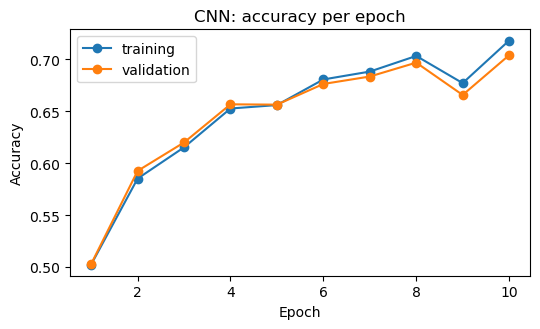

In [7]:
torch.manual_seed(42)
cnn_history = train_classifier(cnn, X_fit, y_fit, X_val, y_val)
print("CNN: validation accuracy by epoch =", [round(a, 3) for a in cnn_history["validation"]])
plot_history(cnn_history, "CNN: accuracy per epoch")

### Question 8 — Open the test images once

Now the test boards, opened once for each model. The first number is Lab 4's PCA-plus-logistic result on the same 3,134 images.

PCA + logistic (Lab 4)   test accuracy = 0.6331
dense network            test accuracy = 0.5491
CNN                      test accuracy = 0.7001


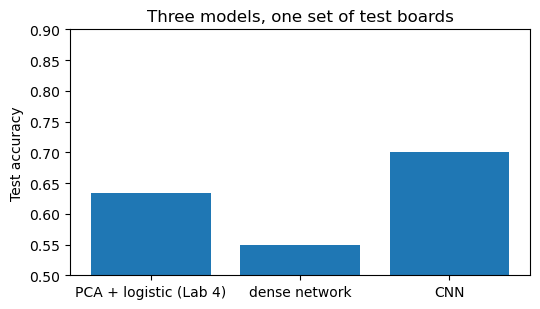

In [8]:
# The test boards, opened once for each model. The first number is Lab 4's result on the same images.
test_scores = {
    "PCA + logistic (Lab 4)": 0.6331,
    "dense network": accuracy(mlp, X_test, y_test),
    "CNN": accuracy(cnn, X_test, y_test),
}
for name, value in test_scores.items():
    print(f"{name:24s} test accuracy = {value:.4f}")

plt.figure(figsize=(5.5, 3.2))
plt.bar(list(test_scores), list(test_scores.values()))
plt.ylim(0.5, 0.9)
plt.ylabel("Test accuracy")
plt.title("Three models, one set of test boards")
plt.tight_layout()
plt.savefig(RESULTS / "three_models_one_set_of_test_boards.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 9 — Inspect the CNN's mistakes

Which types does the CNN still confuse? Recall per type, a confusion matrix, and the misclassified images themselves answer that.

test recall by type:
live knot          0.448
quartzity          0.679
resin              0.721
knot with crack    0.737
crack              0.745
marrow             0.794
dead knot          0.858


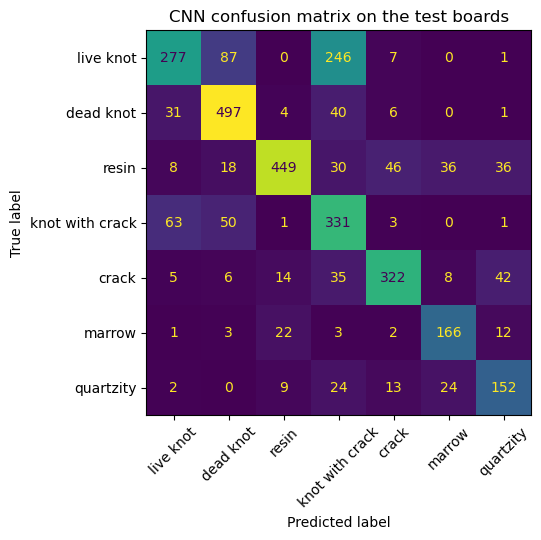

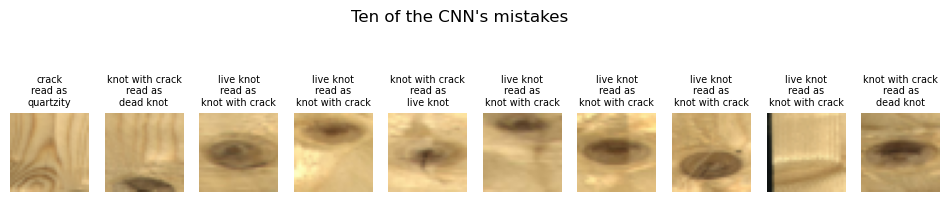

In [9]:
test_pred = predict(cnn, X_test)
truth, guess = y_test.cpu().numpy(), test_pred.cpu().numpy()

# Recall within each type: of the test images that truly are type c, how many did the CNN call c?
per_class = pd.Series([(guess[truth == c] == c).mean() for c in range(7)], index=class_names)
print("test recall by type:\n" + per_class.round(3).sort_values().to_string())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(truth, guess, display_labels=class_names, colorbar=False,
                                        xticks_rotation=45, ax=ax)
ax.set_title("CNN confusion matrix on the test boards")
plt.tight_layout()
plt.savefig(RESULTS / "cnn_confusion_matrix_on_the_test_boards.png", dpi=160, bbox_inches="tight")
plt.show()

# The first ten test images the CNN got wrong.
wrong = torch.nonzero(test_pred != y_test).flatten()[:10]
fig, axes = plt.subplots(1, len(wrong), figsize=(12, 1.9))
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i].permute(1, 2, 0).cpu())
    ax.set_title(f"{class_names[int(y_test[i])]}\nread as\n{class_names[int(test_pred[i])]}", fontsize=7)
    ax.axis("off")
plt.suptitle("Ten of the CNN's mistakes", y=1.25)
plt.savefig(RESULTS / "ten_of_the_cnn_s_mistakes.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 10 — Look at the learned filters

What did the first layer learn? Its sixteen filters are $3\times3$ grids of weights for each colour; added over the three colours, they can be drawn directly, along with the sixteen maps they make of one test image.

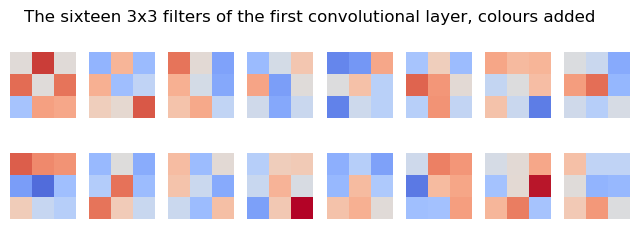

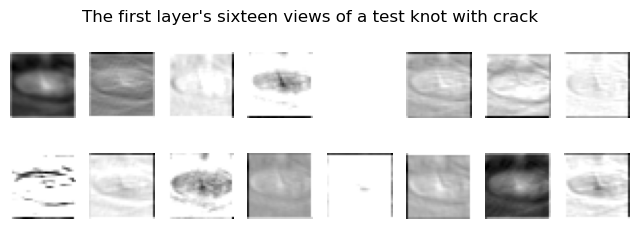

In [10]:
# The first layer's sixteen 3 x 3 filters, with their three colour layers added together
# (blue negative, red positive), so each one can be drawn as a small grid of weights.
filters = cnn[0].weight.detach().cpu().sum(dim=1)                  # 16 x 3 x 3
limit = filters.abs().max()
fig, axes = plt.subplots(2, 8, figsize=(8, 2.4))
for ax, kernel in zip(axes.flat, filters):
    ax.imshow(kernel, cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.axis("off")
plt.suptitle("The sixteen 3x3 filters of the first convolutional layer, colours added", y=1.02)
plt.savefig(RESULTS / "the_sixteen_3x3_filters_of_the_first_convolutional_layer.png", dpi=160, bbox_inches="tight")
plt.show()

# What the first layer (convolution, then ReLU) makes of one test image: sixteen feature maps.
maps = cnn[1](cnn[0](X_test[:1])).detach().cpu()[0]
fig, axes = plt.subplots(2, 8, figsize=(8, 2.4))
for ax, fmap in zip(axes.flat, maps):
    ax.imshow(fmap, cmap="gray_r")
    ax.axis("off")
plt.suptitle(f"The first layer's sixteen views of a test {class_names[int(y_test[0])]}", y=1.02)
plt.savefig(RESULTS / "the_first_layer_s_sixteen_views.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** The CNN has 136,679 weights, a third of the dense network's, arranged differently: its filters are reused at every position of the image. It reaches 0.704 validation accuracy after 10 epochs, still rising. On the test boards, Lab 4's PCA and logistic regression scores 0.633, the dense network only 0.549, and the CNN 0.700: more weights did not help the dense network, while the CNN's structure did. Per type, dead knots are found 86% of the time and live knots only 45%, most often read as knots with cracks, the same blur among knot types that Lab 4 showed. Several first-layer filters have a warm side and a cool side: they respond to an edge in one direction, and nobody told the network to look for edges.

**Checkpoint: before you move on**

- The CNN has 136,679 weights and reaches 0.704 validation accuracy after 10 epochs.
- Test accuracy: 0.633 for Lab 4's PCA model, 0.549 for the dense network, 0.700 for the CNN.
- Live knots are found only 45% of the time, most often read as knots with cracks.

## Part D — Save the weights with a card

**Goal.** Save the weights with a model card, and check that they reload.

*Question 11 · Data: the trained CNN*

### Question 11 — Save the weights with a card

`torch.save` writes the learned weights (the *state dict*) to a file. Loading them requires building the same architecture first, which is why `make_cnn` and the model card belong beside the file. The reloaded model is checked against the in-memory one before the file is trusted.

In [11]:
# The weights (the "state dict") go to one file ...
weights_path = MODELS / "wood_cnn.pt"
torch.save(cnn.state_dict(), weights_path)

# ... and the card records what is needed to use them.
card = {
    "task": "classify 32x32 colour photos of wood surface defects (seven types)",
    "classes": class_names,
    "input": "tensor of shape (n, 3, 32, 32), pixel values divided by 255",
    "architecture": "make_cnn() in Lab 7: conv16-pool-conv32-pool-dense64-dense7",
    "training": {"epochs": 10, "learning_rate": 1e-3, "batch_size": 128, "seed": 42},
    "test_accuracy": round(test_scores["CNN"], 4),
    "torch_version": torch.__version__,
    "trained_on": str(DEVICE),
}
(MODELS / "wood_cnn_card.json").write_text(json.dumps(card, indent=2))

# To load the weights, build the same network first; then check it predicts exactly as before.
restored = make_cnn().to(DEVICE)
restored.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
same = torch.equal(predict(restored, X_test), test_pred)
size_kb = weights_path.stat().st_size / 1024
print(f"saved {weights_path.name} ({size_kb:.0f} KB); reload reproduces predictions: {same}")

saved wood_cnn.pt (537 KB); reload reproduces predictions: True


**What the output shows.** `wood_cnn.pt` holds 537 KB of weights; the card records the seven types, the input format, the architecture, the training settings and the test score. The restored network reproduces every test prediction.

**Checkpoint: before you move on**

- `wood_cnn.pt` is 537 KB, and the reloaded network reproduces every test prediction.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 12 — Save the evidence

In [12]:
curves = pd.DataFrame({
    "epoch": range(1, len(mlp_history["train"]) + 1),
    "mlp_train": mlp_history["train"], "mlp_validation": mlp_history["validation"],
    "cnn_train": cnn_history["train"], "cnn_validation": cnn_history["validation"],
})
curves.round(4).to_csv(RESULTS / "training_curves.csv", index=False)
pd.Series(test_scores, name="test_accuracy").rename_axis("model").round(4).to_csv(RESULTS / "metrics.csv")
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['cnn_accuracy_per_epoch.png', 'cnn_confusion_matrix_on_the_test_boards.png', 'dense_network_accuracy_per_epoch.png', 'metrics.csv', 'one_training_image_of_each_type.png', 'ten_of_the_cnn_s_mistakes.png', 'the_first_layer_s_sixteen_views.png', 'the_sixteen_3x3_filters_of_the_first_convolutional_layer.png', 'three_models_one_set_of_test_boards.png', 'training_curves.csv']


## Try it yourself

Train the CNN for 25 epochs and read the accuracy curves: does the validation curve stop improving, and what is the training curve doing by then? Then build a CNN with only the first convolutional block (delete the second `Conv2d`, `ReLU` and `MaxPool2d`; the flattened size becomes $16\times16\times16$) and see whether the second block earns its keep.

Attempt it in the cell below before reading the solution.

### Question 13 — Try it yourself

In [13]:
# Your work here

### One solution

The CNN trained for 25 epochs, then a one-block CNN.

### Question 14 — One solution

25 epochs: best validation 0.7408 at epoch 24; last epoch: training 0.7490, validation 0.7361


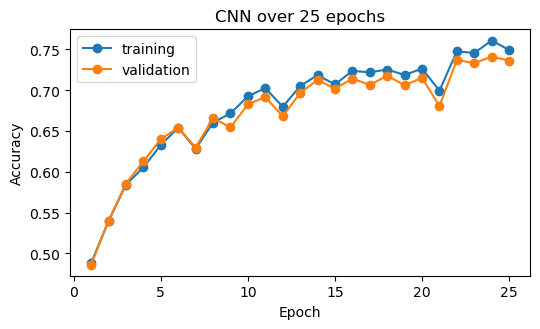

one-block CNN: weights = 263111  test accuracy = 0.6812
two-block CNN: weights = 136679  test accuracy = 0.7001


In [14]:
# Part 1: the same CNN, trained for 25 epochs.
torch.manual_seed(42)
long_run = make_cnn().to(DEVICE)
long_history = train_classifier(long_run, X_fit, y_fit, X_val, y_val, epochs=25)
best = int(np.argmax(long_history["validation"])) + 1
print(f"25 epochs: best validation {max(long_history['validation']):.4f} at epoch {best}; "
      f"last epoch: training {long_history['train'][-1]:.4f}, validation {long_history['validation'][-1]:.4f}")
plot_history(long_history, "CNN over 25 epochs")

# Part 2: a CNN with only the first block; the flattened vector is now 16 x 16 x 16.
def make_one_block_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 x 16 x 16
        nn.Flatten(),                                                             # 4,096
        nn.Linear(16 * 16 * 16, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 7),
    )

torch.manual_seed(42)
one_block = make_one_block_cnn().to(DEVICE)
train_classifier(one_block, X_fit, y_fit, X_val, y_val)
print("one-block CNN: weights =", sum(p.numel() for p in one_block.parameters()),
      " test accuracy =", round(accuracy(one_block, X_test, y_test), 4))
print("two-block CNN: weights =", sum(p.numel() for p in cnn.parameters()),
      " test accuracy =", round(test_scores["CNN"], 4))

**What it shows.** Over 25 epochs the validation accuracy keeps climbing, to 0.741 at epoch 24, and training, at 0.749, is barely ahead of it: this small CNN is still learning and has hardly begun to overfit, so more epochs would pay. The one-block CNN has almost twice the weights, 263,111, because its flattened vector is $16\times16\times16=4{,}096$ long, and it scores lower, 0.681 against 0.700. The second block earns its keep twice: its pooling shrinks the map before the expensive dense layer, and its filters can combine the first layer's edges into larger shapes.